# Preliminary Exploration of Jeopardy! Questions Dataset

In [1]:
import json

with open("JEOPARDY_QUESTIONS1.json", "r", encoding="utf-8") as f:
    data = json.load(f)

In [6]:
print(f"Total questions: {len(data)}")
print(data[0])

Total questions: 216930
{'category': 'HISTORY', 'air_date': '2004-12-31', 'question': "'For the last 8 years of his life, Galileo was under house arrest for espousing this man's theory'", 'value': '$200', 'answer': 'Copernicus', 'round': 'Jeopardy!', 'show_number': '4680'}


In [ ]:
import pandas as pd

df = pd.DataFrame(data)

print(df.shape)
display(df.head())

(216930, 7)


,category,air_date,question,value,answer,round,show_number
0,HISTORY,2004-12-31,"'For the last 8 years of his life, Galileo was...",$200,Copernicus,Jeopardy!,4680
1,ESPN's TOP 10 ALL-TIME ATHLETES,2004-12-31,'No. 2: 1912 Olympian; football star at Carlis...,$200,Jim Thorpe,Jeopardy!,4680
2,EVERYBODY TALKS ABOUT IT...,2004-12-31,'The city of Yuma in this state has a record a...,$200,Arizona,Jeopardy!,4680
3,THE COMPANY LINE,2004-12-31,"'In 1963, live on ""The Art Linkletter Show"", t...",$200,McDonald\'s,Jeopardy!,4680
4,EPITAPHS & TRIBUTES,2004-12-31,"'Signer of the Dec. of Indep., framer of the C...",$200,John Adams,Jeopardy!,4680


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print(f"Number of samples: {len(df):,}")
print(f"Number of columns: {df.shape[1]}")
print("\nColumns and data types:")
print(df.dtypes)

display(df.head(10))

Number of samples: 216,930
Number of columns: 7

Columns and data types:
category       object
air_date       object
question       object
value          object
answer         object
round          object
show_number    object
dtype: object


,category,air_date,question,value,answer,round,show_number
0,HISTORY,2004-12-31,"'For the last 8 years of his life, Galileo was...",$200,Copernicus,Jeopardy!,4680
1,ESPN's TOP 10 ALL-TIME ATHLETES,2004-12-31,'No. 2: 1912 Olympian; football star at Carlis...,$200,Jim Thorpe,Jeopardy!,4680
2,EVERYBODY TALKS ABOUT IT...,2004-12-31,'The city of Yuma in this state has a record a...,$200,Arizona,Jeopardy!,4680
3,THE COMPANY LINE,2004-12-31,"'In 1963, live on ""The Art Linkletter Show"", t...",$200,McDonald\'s,Jeopardy!,4680
4,EPITAPHS & TRIBUTES,2004-12-31,"'Signer of the Dec. of Indep., framer of the C...",$200,John Adams,Jeopardy!,4680
5,3-LETTER WORDS,2004-12-31,"'In the title of an Aesop fable, this insect s...",$200,the ant,Jeopardy!,4680
6,HISTORY,2004-12-31,'Built in 312 B.C. to link Rome & the South of...,$400,the Appian Way,Jeopardy!,4680
7,ESPN's TOP 10 ALL-TIME ATHLETES,2004-12-31,'No. 8: 30 steals for the Birmingham Barons; 2...,$400,Michael Jordan,Jeopardy!,4680
8,EVERYBODY TALKS ABOUT IT...,2004-12-31,"'In the winter of 1971-72, a record 1,122 inch...",$400,Washington,Jeopardy!,4680
9,THE COMPANY LINE,2004-12-31,'This housewares store was named for the packa...,$400,Crate & Barrel,Jeopardy!,4680


In [9]:
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percent": df.isna().mean() * 100
})

display(missing.sort_values("Missing Count", ascending=False))

,Missing Count,Missing Percent
value,3634,1.675195
air_date,0,0.000000
category,0,0.000000
question,0,0.000000
answer,0,0.000000
round,0,0.000000
show_number,0,0.000000


In [10]:
for col in df.select_dtypes(include="object").columns:
    empty_count = df[col].fillna("").str.strip().eq("").sum()
    print(f"{col}: {empty_count:,} empty values")

category: 0 empty values
air_date: 0 empty values
question: 0 empty values
value: 3,634 empty values
answer: 0 empty values
round: 0 empty values
show_number: 0 empty values


In [11]:
print(f"Fully duplicated rows: {df.duplicated().sum():,}")

print(
    f"Duplicated question texts: "
    f"{df.duplicated(subset=['question']).sum():,}"
)

print(
    f"Duplicated question-answer pairs: "
    f"{df.duplicated(subset=['question', 'answer']).sum():,}"
)

Fully duplicated rows: 0
Duplicated question texts: 798
Duplicated question-answer pairs: 379


In [12]:
duplicates = df[
    df.duplicated(subset=["question"], keep=False)
].sort_values("question")

display(duplicates.head(20))

,category,air_date,question,value,answer,round,show_number
76511,PRESIDENTIAL BIOGRAPHIES,2008-10-14,"'""A Time to Heal""'","$2,000",Gerald Ford,Double Jeopardy!,5542
144726,BOOKS BY PRESIDENTS,1998-06-29,"'""A Time to Heal""'",$400,Gerald Ford,Double Jeopardy!,3201
30412,MOVIE LOVE THEMES,1998-05-27,"'""A Whole New World""'",$400,Aladdin,Double Jeopardy!,3178
189941,SONGS FROM DISNEY FILMS,2003-02-20,"'""A Whole New World""'",$800,Aladdin,Double Jeopardy!,4259
59633,WHAT'S THE PITCH?,1996-01-16,"'""A mind is a terrible thing to waste""'",$500,United Negro College Fund (UNCF),Jeopardy!,2622
196438,SLOGANS,1997-10-07,"'""A mind is a terrible thing to waste""'",$500,United Negro College Fund,Jeopardy!,3012
163145,CONVERBS,2000-01-03,"'""A watched pot never"" does this'",$100,boils,Jeopardy!,3531
57777,PROVERBIALLY SPEAKING,2010-05-04,"'""A watched pot never"" does this'",$800,boils,Jeopardy!,5912
78322,PROVERBS,1990-02-01,"'""A watched pot never"" does this'",$600,Boils,Double Jeopardy!,1254
129361,"AUTHOR, AUTHOR!",2010-02-04,"'""Absalom, Absalom!""'",$600,Faulkner,Jeopardy!,5849


Unique categories: 27,995


,Count
category,
BEFORE & AFTER,547
SCIENCE,519
LITERATURE,496
AMERICAN HISTORY,418
POTPOURRI,401
WORLD HISTORY,377
WORD ORIGINS,371
COLLEGES & UNIVERSITIES,351
HISTORY,349


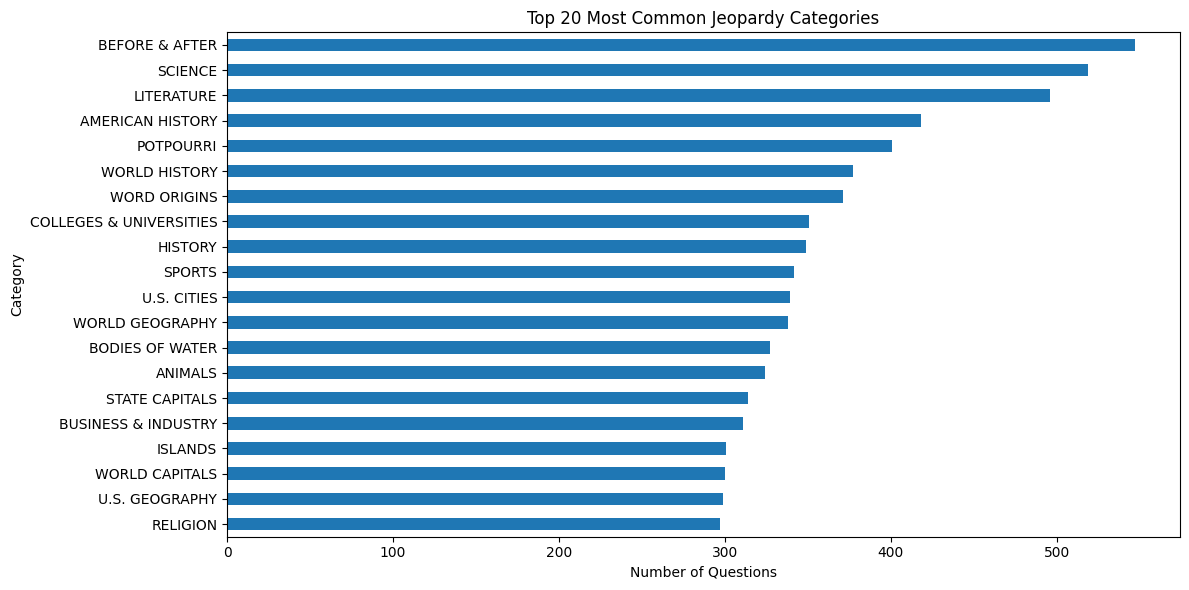

In [13]:
category_counts = df["category"].value_counts()

print(f"Unique categories: {df['category'].nunique():,}")

display(category_counts.head(20).to_frame("Count"))

plt.figure(figsize=(12, 6))
category_counts.head(20).sort_values().plot(kind="barh")

plt.xlabel("Number of Questions")
plt.ylabel("Category")
plt.title("Top 20 Most Common Jeopardy Categories")
plt.tight_layout()
plt.show()

Categories with 1 question: 1,044
Categories with <= 5 questions: 23,118
Categories with >= 20 questions: 1,246
Categories with >= 50 questions: 348


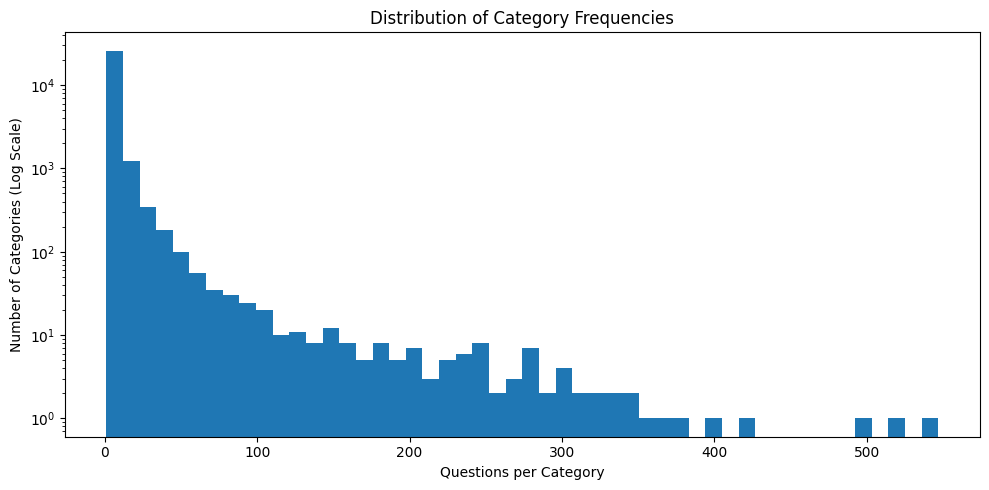

In [14]:
category_counts = df["category"].value_counts()

print(f"Categories with 1 question: {(category_counts == 1).sum():,}")
print(f"Categories with <= 5 questions: {(category_counts <= 5).sum():,}")
print(f"Categories with >= 20 questions: {(category_counts >= 20).sum():,}")
print(f"Categories with >= 50 questions: {(category_counts >= 50).sum():,}")

plt.figure(figsize=(10, 5))
plt.hist(category_counts, bins=50, log=True)

plt.xlabel("Questions per Category")
plt.ylabel("Number of Categories (Log Scale)")
plt.title("Distribution of Category Frequencies")
plt.tight_layout()
plt.show()

count    216930.000000
mean         14.562633
std           5.932564
min           1.000000
25%          11.000000
50%          15.000000
75%          18.000000
max         129.000000
Name: question_word_count, dtype: float64


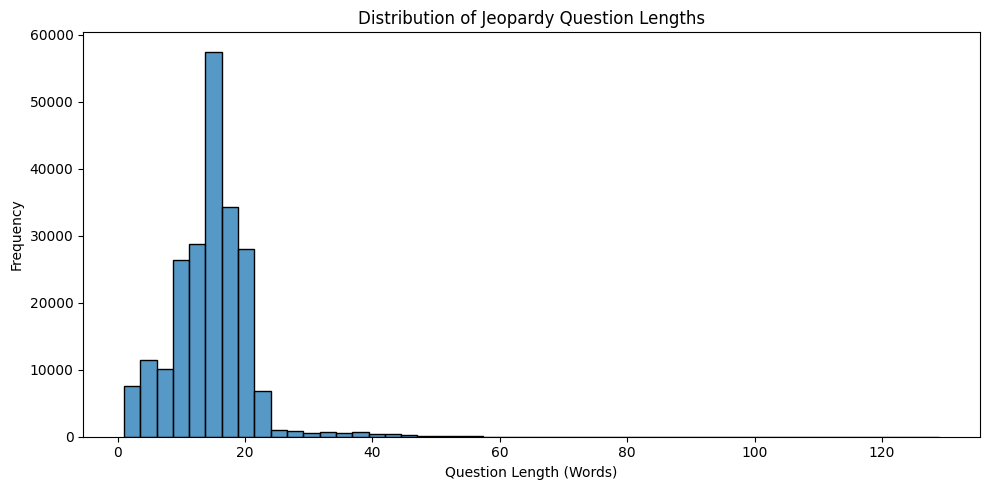

In [15]:
df["question_word_count"] = df["question"].fillna("").str.split().str.len()

print(df["question_word_count"].describe())

plt.figure(figsize=(10, 5))
sns.histplot(df["question_word_count"], bins=50)

plt.xlabel("Question Length (Words)")
plt.ylabel("Frequency")
plt.title("Distribution of Jeopardy Question Lengths")
plt.tight_layout()
plt.show()

In [16]:
display(
    df.nlargest(10, "question_word_count")[
        ["category", "question", "answer", "question_word_count"]
    ]
)

,category,question,answer,question_word_count
205763,WE LOVE BROADWAY,"'(<a href=""http://www.j-archive.com/media/2006...",The Wizard of Oz,129
100604,MUSIC,"'(<a href=""http://www.j-archive.com/media/2006...",the Empire State Building,99
179473,JERSEY BOYS,"'(<a href=""http://www.j-archive.com/media/2006...",The Four Seasons,86
24171,THEATRE: HOW NOVEL!,"'(<a href=""http://www.j-archive.com/media/2006...",Oprah Winfrey,81
7278,MUSICAL THEATRE,'1966 Jerry Herman musical that features the <...,Mame,75
72152,POP GOES THE MUSICAL,"'(<a href=""http://www.j-archive.com/media/2006...",ABBA,75
88238,THE NATIONAL ARCHIVES,"'(<a href=""http://www.j-archive.com/media/2010...",the Declaration of Independence,68
101948,BACK AT THE CBC,"'(<a href=""http://www.j-archive.com/media/2009...",an audition,68
22207,THE GREATEST IN SPORTS WITH MIKE & MIKE,"'(<a href=""http://www.j-archive.com/media/2010...",instant replay,67
436,RVs,"'(<a href=""http://www.j-archive.com/media/2010...",Mae West,65


count    216930.000000
mean          1.905486
std           1.132816
min           1.000000
25%           1.000000
50%           2.000000
75%           2.000000
max          22.000000
Name: answer_word_count, dtype: float64


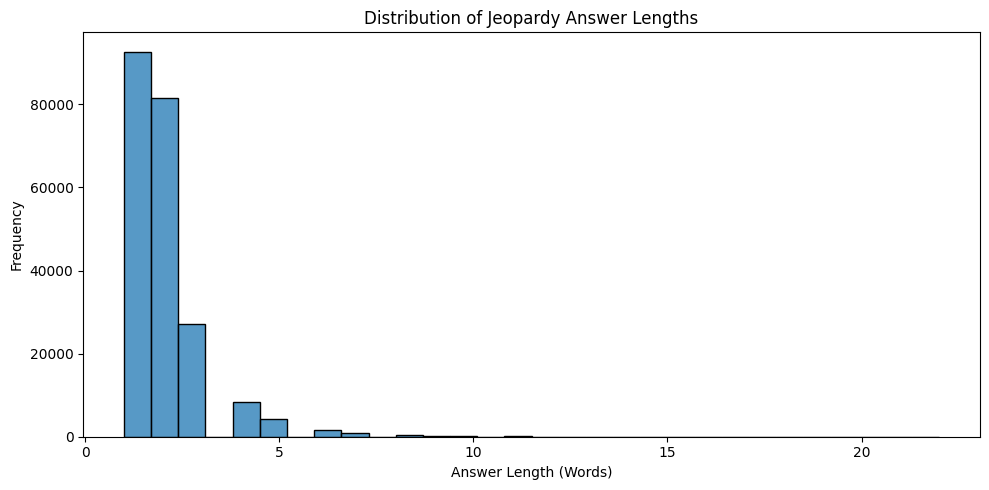

In [17]:
df["answer_word_count"] = df["answer"].fillna("").str.split().str.len()

print(df["answer_word_count"].describe())

plt.figure(figsize=(10, 5))
sns.histplot(df["answer_word_count"], bins=30)

plt.xlabel("Answer Length (Words)")
plt.ylabel("Frequency")
plt.title("Distribution of Jeopardy Answer Lengths")
plt.tight_layout()
plt.show()

In [18]:
total = len(df)

print(f"Single-word answers: {(df['answer_word_count'] == 1).sum() / total:.2%}")
print(f"1–3 word answers: {(df['answer_word_count'] <= 3).sum() / total:.2%}")
print(f"Answers over 10 words: {(df['answer_word_count'] > 10).sum() / total:.2%}")

Single-word answers: 42.73%
1–3 word answers: 92.80%
Answers over 10 words: 0.06%


In [19]:
print(df["value"].value_counts(dropna=False).head(30))

value
$400      42244
$800      31860
$200      30455
$600      20377
$1000     19539
$1200     11331
$2000     11243
$1600     10801
$100       9029
$500       9016
$300       8663
None       3634
$1,000     2101
$2,000     1586
$3,000      769
$1,500      546
$1,200      441
$4,000      349
$1,600      239
$2,500      232
$5,000      231
$1,400      228
$700        203
$1,800      182
$2,200      147
$2,400      127
$900        114
$6,000       85
$2,600       83
$1,300       75
Name: count, dtype: int64


count      213296.0
mean     752.595923
std      637.855303
min             5.0
25%           400.0
50%           600.0
75%          1000.0
max         18000.0
Name: value_numeric, dtype: Float64


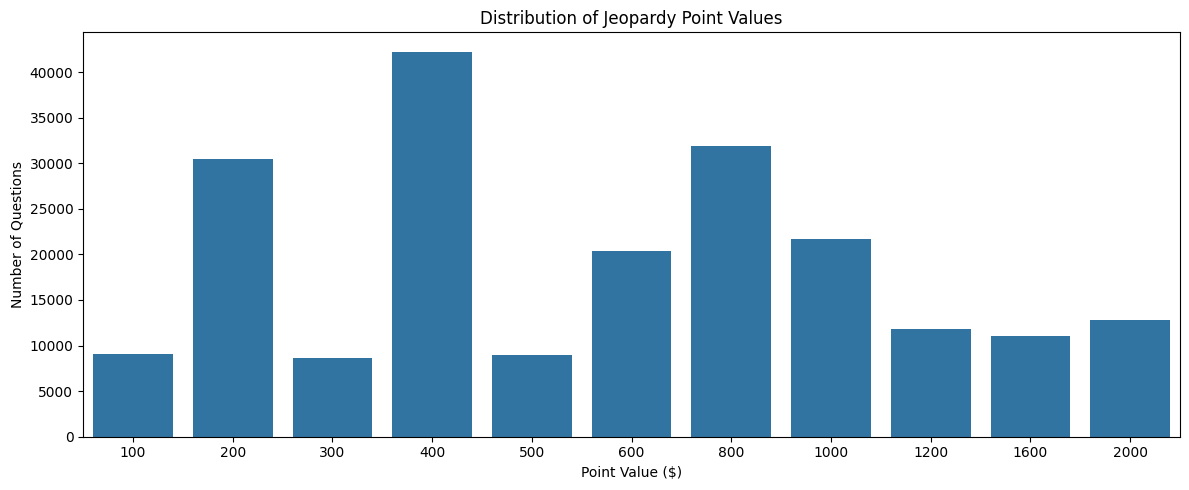

In [20]:
df["value_numeric"] = pd.to_numeric(
    df["value"].astype("string").str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

print(df["value_numeric"].describe())

plt.figure(figsize=(12, 5))
sns.countplot(
    data=df[df["value_numeric"].isin([100, 200, 300, 400, 500, 600, 800, 1000, 1200, 1600, 2000])],
    x="value_numeric",
    order=[100, 200, 300, 400, 500, 600, 800, 1000, 1200, 1600, 2000]
)

plt.xlabel("Point Value ($)")
plt.ylabel("Number of Questions")
plt.title("Distribution of Jeopardy Point Values")
plt.tight_layout()
plt.show()

,value_numeric,mean,median,count
0,5,18.666667,17.0,9
1,20,12.000000,12.0,1
2,22,21.000000,21.0,1
3,50,12.000000,12.0,1
4,100,13.168900,14.0,9029
5,200,13.836907,14.0,30455
6,250,16.800000,18.0,5
7,300,13.577052,14.0,8663
8,350,9.500000,9.5,2
9,367,22.000000,22.0,1


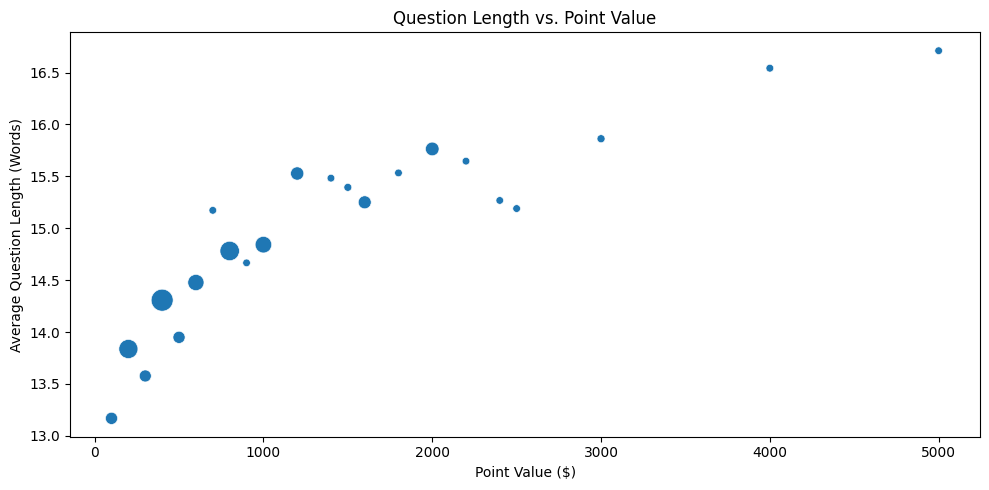

In [21]:
value_length = (
    df.dropna(subset=["value_numeric"])
      .groupby("value_numeric")["question_word_count"]
      .agg(["mean", "median", "count"])
      .reset_index()
)

display(value_length.head(20))

plot_data = value_length[value_length["count"] >= 100]

plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=plot_data,
    x="value_numeric",
    y="mean",
    size="count",
    sizes=(30, 250),
    legend=False
)

plt.xlabel("Point Value ($)")
plt.ylabel("Average Question Length (Words)")
plt.title("Question Length vs. Point Value")
plt.tight_layout()
plt.show()